# 03 Recommenders

This notebook contains everything after the EDA. Part 1 sets up the evaluation that every recommender uses. The following parts build and evaluate the recommenders, and the last parts compare them and estimate the business value.

| Part | Content |
|---|---|
| 1 | Evaluation setup |
| 2 | Non-personalized recommenders (random, popular, demographic) |
| 3 | Collaborative filtering |
| 4 | Content-based |
| 5 | Hybrid |
| 6 | Context-aware |
| 7 | Bandits |
| 8 | Final comparison and business value |

The data is the cleaned sample from `01_preprocessing.ipynb`, described in `02_eda.ipynb`.

# Part 1. Evaluation setup

Every recommender is compared on the same split, the same definition of a relevant anime and the same metric functions. This part makes those choices once and checks them.

## 1.1 Libraries

In [1]:
%pip install -q pandas pyarrow scikit-surprise rexmex "seaborn>=0.13" "plotly>=5" funcsigs six
%pip install -q --no-deps recmetrics

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


**Why recmetrics is installed without its dependencies.** recmetrics 0.1.5 requires pandas below 2.0 and seaborn below 0.12. The course notebooks work around this by switching Colab to Python 3.11 and installing old versions of pandas, numpy and seaborn [4, p. 1]. That Colab runtime (2025.07) is no longer offered, and current runtimes use Python 3.12 [10], for which pandas 1.5 is not available. Installing recmetrics with `--no-deps` on top of current pandas, seaborn and plotly avoids the conflict. The metric functions themselves only use numpy, pandas, scipy and scikit-learn, which work in current versions, and they return the same values as the examples in the S08 notebook.

In [2]:
from collections import defaultdict
import html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import recmetrics
import sklearn.metrics as metrics
from rexmex import ClassificationMetricSet, ScoreCard
from rexmex.metrics.ranking import mean_average_precision_at_k, mean_average_recall_at_k
from sklearn.model_selection import TimeSeriesSplit
from surprise import AlgoBase, Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

# Set a concrete seed to make results reproducible
import random
my_seed = 1234
random.seed(my_seed)
np.random.seed(my_seed)

## 1.2 Data, explicit and implicit feedback

In [3]:
interactions_df = pd.read_parquet("../data/processed/interactions.parquet")
users_df = pd.read_parquet("../data/processed/users.parquet")
anime_df = pd.read_parquet("../data/processed/anime.parquet")

# Some titles contain HTML codes such as &#039;
anime_df["title"] = anime_df["title"].map(html.unescape)

# Explicit feedback: rows with a score
ratings_df = interactions_df[interactions_df["score"] > 0].reset_index(drop=True)
print("Explicit ratings:", len(ratings_df))

status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}
print()
print("Average score per status")
print(ratings_df.groupby(ratings_df["status"].map(status_names))["score"].agg(["mean", "count"]).round(2))

Explicit ratings: 977062

Average score per status
           mean   count
status                 
completed  7.66  893971
dropped    4.93   33828
on hold    7.20   22644
watching   7.98   26619


In [4]:
# Explicit relevance: a score of 8 or more (see 02_eda)
relevant_score = 8

# Implicit feedback: 1 for completed or watching, 0 for on hold, dropped and plan to watch
interactions_df["implicit"] = interactions_df["status"].isin([1, 2]).astype(int)
print("Share of interactions labelled 1:", round(interactions_df["implicit"].mean(), 3))

Share of interactions labelled 1: 0.686


**Implicit feedback.** An interaction counts as positive (1) when the anime is completed or being watched. On hold, dropped and plan to watch count as 0.

The reason is that implicit feedback should mark consumption the user was happy with, not every action. A purchase or a full stream is a positive implicit rating, while returning a product is a negative one [2, p. 83]. Turning events into 0 and 1 is a design choice that has to be justified for each dataset [3, p. 16]. The scores in this data support the split. Users who rated an anime they are still watching give it 7.98 on average and completed anime get 7.66. Dropped anime get only 4.93, so dropping is clearly a negative signal. On hold anime get 7.20, below both positive statuses and below the relevance threshold of 8 from 02_eda.

A counterargument is that plan to watch also shows interest, since the user chose to add the anime. But the user has not watched it, so it cannot tell whether they liked it. It is closer to a product view than a purchase, which is labelled 0 in the course example [3, p. 16]. On hold is the less clear case, since its average is still positive. It is labelled 0 because the user stopped watching, and only 2.3% of the rated interactions have this status, so the choice has little effect on the results. With this rule 68.6% of all interactions are positive.

## 1.3 Train and test splits
### Random split

In [5]:
reader = Reader(rating_scale=(1, 10))
data = Dataset.load_from_df(ratings_df[["user_id", "anime_id", "score"]], reader)

trainset, testset = train_test_split(data, test_size=0.2, random_state=my_seed)

train_items = {trainset.to_raw_iid(i) for i in trainset.all_items()}
test_df = pd.DataFrame(testset, columns=["user_id", "anime_id", "score"])

print("Train ratings:", trainset.n_ratings, " test ratings:", len(testset))
print("Users in the test set:", test_df["user_id"].nunique(), "of", trainset.n_users)
print("Test anime that are not in the train set:", len(set(test_df["anime_id"]) - train_items))
print()
print("Test ratings per user")
print(test_df.groupby("user_id").size().describe().round(1))

Train ratings: 781649  test ratings: 195413
Users in the test set: 4982 of 5000
Test anime that are not in the train set: 57

Test ratings per user
count    4982.0
mean       39.2
std        46.2
min         1.0
25%        11.0
50%        25.0
75%        50.0
max       592.0
dtype: float64


### Split per user

In [6]:
def split_per_user(ratings_df, test_size=0.2):
    # Each user puts test_size of their own ratings in the test set
    test_df = ratings_df.groupby("user_id", group_keys=False).sample(frac=test_size, random_state=my_seed)
    train_df = ratings_df.drop(test_df.index)
    trainset = Dataset.load_from_df(train_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    testset = list(test_df[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    return trainset, testset

trainset_per_user, testset_per_user = split_per_user(ratings_df)
test_per_user_df = pd.DataFrame(testset_per_user, columns=["user_id", "anime_id", "score"])

print("Users in the test set:", test_per_user_df["user_id"].nunique())
print("Fewest test ratings for a user:", test_per_user_df.groupby("user_id").size().min())

Users in the test set: 5000
Fewest test ratings for a user: 2


### Cross-validation through time (CVTT)

In [7]:
# Ordering by time and resetting the index is needed, since TimeSeriesSplit is based on the index
ratings_by_time_df = ratings_df.sort_values("last_updated").reset_index(drop=True)
tscv = TimeSeriesSplit(n_splits=5)

rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    rows.append({
        "fold": fold,
        "train until": train_fold["last_updated"].max().date(),
        "test until": test_fold["last_updated"].max().date(),
        "test users with no train history %": round(100 * (1 - test_fold["user_id"].isin(train_fold["user_id"]).mean()), 1),
        "test ratings on anime not in train %": round(100 * (1 - test_fold["anime_id"].isin(train_fold["anime_id"]).mean()), 1),
        "mean test score": round(test_fold["score"].mean(), 2),
    })
pd.DataFrame(rows)

,fold,train until,test until,test users with no train history %,test ratings on anime not in train %,mean test score
0,1,2010-05-06,2012-06-16,56.2,28.1,7.67
1,2,2012-06-16,2014-01-15,47.7,30.3,7.62
2,3,2014-01-15,2015-06-30,34.9,28.5,7.53
3,4,2015-06-30,2016-10-28,31.3,31.1,7.50
4,5,2016-10-28,2018-05-22,25.0,26.7,7.39


**Which split to use.** The random 80/20 split is the main split for comparing models. The per-user split and CVTT are used as checks on the final candidates.

The random split is the standard method in the course [5, p. 4], and it represents almost everything in the test set. 4,982 of the 5,000 users have test ratings, the median user has 25, and only 57 test anime are missing from training. The same split is used by every notebook through the split in 1.3, so all models are tested on exactly the same ratings.

The per-user split puts 20% of every user's ratings in the test set. It solves the problem that a random split can leave a user with no test data by chance [5, p. 28]. Here it only adds the 18 missing users, and every user gets at least 2 test ratings. Because the gain is small, it is used as a robustness check rather than the main split. It is also one of the advanced evaluation options in the course [9].

CVTT trains on the past and tests on later ratings, which is how the system would work in production [5, p. 27]. The table shows why it cannot be the main split for every model. In the first fold 56.2% of the test users have no history in the training data, and even in the last fold 25.0% have none. Between 26.7% and 31.1% of test ratings are on anime that did not exist in the training period. A collaborative filtering model cannot score these users or anime, so CVTT mixes the cold start problem into every comparison. It is still essential for two parts of the project. The average test score falls from 7.67 to 7.39 across the folds, the same downward drift found in 02_eda, so a random split lets models learn from the future. CVTT therefore measures how the final system and the context-aware models perform on genuinely new data.

The main counterargument to the random split is exactly this leakage of future ratings into training, which makes all results slightly optimistic. The leakage affects every model in the same way, so it does not change which model ranks first. The final candidates are re-tested with CVTT to confirm the choice holds on future data.

## 1.4 Metric functions

`get_top_n` and `ndcg_multiple_users` are the functions from the S10 notebook. `test_ranking_metrics` adds MAP and MAR from rexmex (S08). `top_n_unseen` ranks every anime a user has not rated, which is what a homepage would show.

In [ ]:
def get_top_n(predictions, n=10, solve_ties=False):
    top_n = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        top_n[uid].append((iid, est))
    for uid, user_ratings in top_n.items():
        if solve_ties:
            user_ratings.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]
    return top_n


def ndcg_multiple_users(relevant_items_all_users, predictions_ranking_all_users, k=5):
    ndcg_list = []
    for i in range(len(relevant_items_all_users)):
        # Skip users with only 1 item in the test data, as no NDCG can be computed
        if len(relevant_items_all_users[i]) > 1:
            ndcg = metrics.ndcg_score([relevant_items_all_users[i]], [predictions_ranking_all_users[i]], k=k)
            ndcg_list.append(ndcg)
    return np.mean(ndcg_list)

In [9]:
def accuracy_metrics(predictions):
    return {"RMSE": accuracy.rmse(predictions, verbose=False),
            "MAE": accuracy.mae(predictions, verbose=False)}


def test_ranking_metrics(predictions, k=10, min_test_items=1):
    # Rank each user's test anime by the predicted score
    df = pd.DataFrame(predictions)
    by_user = df.groupby("uid")[["iid", "r_ui", "est"]].agg(list)
    by_user = by_user[by_user["iid"].str.len() >= min_test_items]

    # MAP and MAR need the relevant anime and the ranking as lists of ids
    relevant_items, rankings = [], []
    for iids, scores, ests in zip(by_user["iid"], by_user["r_ui"], by_user["est"]):
        relevant = [i for i, s in zip(iids, scores) if s >= relevant_score]
        if relevant:
            relevant_items.append(relevant)
            rankings.append([i for _, i in sorted(zip(ests, iids), reverse=True)])

    return {f"NDCG@{k}": ndcg_multiple_users(by_user["r_ui"].tolist(), by_user["est"].tolist(), k=k),
            f"MAP@{k}": mean_average_precision_at_k(relevant_items, rankings, k=k),
            f"MAR@{k}": mean_average_recall_at_k(relevant_items, rankings, k=k),
            "users": len(by_user)}

In [10]:
def eval_users(trainset, n=1000):
    # The same random users for every model
    raw_users = sorted(trainset.to_raw_uid(u) for u in trainset.all_users())
    rng = np.random.default_rng(my_seed)
    return list(rng.choice(raw_users, size=n, replace=False))


def top_n_unseen(algo, trainset, users, n=10, solve_ties=False):
    # Same result as build_anti_testset() + test() + get_top_n(), but one user at a time to save memory
    rng = np.random.default_rng(my_seed)
    all_items = [trainset.to_raw_iid(i) for i in trainset.all_items()]
    top_n = {}
    for uid in users:
        seen = {trainset.to_raw_iid(i) for i, _ in trainset.ur[trainset.to_inner_uid(uid)]}
        scores = [(iid, algo.predict(uid, iid).est) for iid in all_items if iid not in seen]
        if solve_ties:
            scores.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            rng.shuffle(scores)  # ties are broken at random
            scores.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = [iid for iid, _ in scores[:n]]
    return top_n


def homepage_hits(top_n, testset):
    # Relevant test anime among the 10 anime shown to each user
    relevant = defaultdict(set)
    for uid, iid, r in testset:
        if r >= relevant_score:
            relevant[uid].add(iid)
    hits = [len(set(items) & relevant[uid]) for uid, items in top_n.items()]
    return {"hits out of 10": np.mean(hits),
            "users with at least 1 hit %": 100 * np.mean([h > 0 for h in hits])}


genres_df = anime_df.set_index("anime_id")["genre"].fillna("").str.get_dummies(sep=", ")

def beyond_accuracy_metrics(top_n, trainset):
    # Use a model fitted on build_full_trainset(), never on a train and test split
    catalog = [trainset.to_raw_iid(i) for i in trainset.all_items()]
    lists = list(top_n.values())
    return {"coverage %": recmetrics.prediction_coverage(lists, catalog),
            "personalization": recmetrics.personalization(lists),
            "intra-list similarity": recmetrics.intra_list_similarity(lists, genres_df)}

## 1.5 Check of the setup

The setup is checked with three recommenders whose behaviour is known in advance. The random and popular classes are written as in the S10 notebook. The popular one stores the averages in a dictionary instead of a dataframe, which gives the same predictions much faster. Part 2 evaluates and interprets these baselines in full. Here they only check that the evaluation code behaves as expected.

In [11]:
class MyRandomAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        return np.random.normal(loc=self.train_mean, scale=self.train_std)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = [r for (_, _, r) in self.trainset.all_ratings()]
        self.train_mean = np.mean(ratings)
        self.train_std = np.std(ratings)
        return self


class MyPopularAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        # Anime not seen in training get the global mean
        return self.mean_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        self.mean_rating_per_item = ratings.groupby("item")["rating"].mean().to_dict()
        return self


check_models = {
    "Random": MyRandomAlgorithm(),
    "Popular": MyPopularAlgorithm(),
    "SVD (default)": SVD(random_state=my_seed),
}

### Accuracy and ranking of the test items

In [12]:
rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    predictions = algo.test(testset)
    row = {"model": name}
    row.update(accuracy_metrics(predictions))
    row.update(test_ranking_metrics(predictions))
    row["NDCG@10 (users with 20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,users,NDCG@10 (users with 20+ test items)
model,,,,,,,
Random,2.346,1.859,0.860,0.556,0.387,4982,0.812
Popular,1.552,1.184,0.932,0.784,0.509,4982,0.912
SVD (default),1.247,0.930,0.938,0.800,0.520,4982,0.919


**Ranking metrics on the test items overstate weak models.** The ordering is as expected. SVD is best on every metric, popular comes second and random is last [5, pp. 8-9]. But random still reaches an NDCG@10 of 0.860 and a MAP@10 of 0.556.

Two effects explain this. First, these metrics only rank each user's own test ratings. Many users have few test ratings, and a short list leaves little room for a bad ranking [7, pp. 14-15]. Second, 55.7% of all ratings are 8 or more (02_eda), so even a random order puts relevant anime near the top. The difference between an 8 and a 9 also barely moves NDCG [7, p. 17].

The evidence is in the last column. For users with at least 20 test ratings, the NDCG of random drops from 0.860 to 0.812, while SVD only drops from 0.938 to 0.919. The gap between random and SVD grows from 0.078 to 0.107. Longer test lists make it possible to rank badly, so the metric separates the models better. For this reason every notebook reports NDCG for users with 20 or more test items next to the overall value.

The RMSE results follow the same order. Random has an RMSE of 2.35 because it draws scores around the mean with the full spread of the data. Popular reduces it to 1.55 and SVD to 1.25. One could argue RMSE alone is enough to rank models, but RMSE measures every predicted score, while the homepage only shows the top 10. A model can predict well on average and still rank the top poorly, which is why ranking metrics are needed as well [2, p. 227].

### Top 10 over the whole catalog

In [13]:
users = eval_users(trainset)

rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    top_n = top_n_unseen(algo, trainset, users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(homepage_hits(top_n, testset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,hits out of 10,users with at least 1 hit %
model,,
Random,0.028,2.7
Popular,0.000,0.0
SVD (default),0.652,39.6


**The homepage metric is the closest to the business question.** It ranks every anime the user has not rated, takes the top 10 and counts how many are relevant anime from the user's test set. SVD finds 0.652 relevant anime per 10 shown, against 0.028 for random. That is about 23 times more, and 39.6% of users get at least one hit against 2.7% with random.

Popular gets 0 hits. Its top 10 consists of anime with an average of 10 from a single rating. Twelve anime in the training data have exactly one rating of 10, so the plain average puts them above every well-known title. Nobody else has rated them, so they never match a test rating. This is a weakness of the plain average, and Part 2 fixes it with a Bayesian average.

The absolute numbers are low on purpose and should not be read as the real hit rate. The metric only counts an anime as a hit if the user rated it in the test set. An anime the user would have loved but never rated counts as a miss. Offline evaluation is therefore biased towards what users already found by themselves [6, pp. 96-97]. The same bias applies to every model, so the ratio between models is meaningful even though the level is too low. This also explains why random gets 0.028 here and 0.16 in 02_eda. The EDA counted all of a user's relevant anime, while here only the 20% in the test set can count.

The same 1,000 users are used for every model. Ranking all unrated anime for 1,000 users means about 6 million predictions per model, which is the size of the anti-testset of the course example (610 users and 9,724 movies) [5, p. 2]. All 5,000 users would take five times longer for the memory-based models in Part 3.

In [14]:
full_trainset = data.build_full_trainset()
full_users = eval_users(full_trainset)

rows = []
for name, algo in check_models.items():
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(beyond_accuracy_metrics(top_n, full_trainset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,coverage %,personalization,intra-list similarity
model,,,
Random,80.52,0.998,0.180
Popular,0.31,0.077,0.141
SVD (default),14.58,0.918,0.269


**The beyond-accuracy metrics behave as theory predicts, which confirms the setup is correct.** Random reaches 80.5% coverage, popular 0.3% and SVD 14.6%. Personalization is 0.998 for random, 0.077 for popular and 0.918 for SVD. This is the expected order. Random should have the highest coverage and personalization, popular the lowest, and collaborative filtering in between [5, p. 20; 8].

These metrics are computed on `build_full_trainset()`, with every anime the user has not rated as candidates. They do not need a test set because they describe what is shown, not whether it is liked. A train and test split would only use the small fraction of known ratings and make all recommenders look alike on coverage [8]. Random cannot reach 100% here because 1,000 users with 10 anime each fill 10,000 slots out of 5,980 anime, and random draws repeat. The expected share of distinct anime is about 81%, which matches the result.

The setup needed one fix to get there. Surprise clips predictions to the rating scale, so the 7.8% of random predictions above 10 all become exactly 10. Each user then has hundreds of anime tied at 10, and a stable sort keeps them in the same catalogue order for everyone. In a first run this gave random a coverage of only 5.3%. Ties are now broken at random, which is the intended default [5, p. 17]. Popular uses `solve_ties=True` instead, so it gives every user the same list [5, p. 18]. Its personalization is still not exactly 0, because anime a user already rated are removed from their list.

Intra-list similarity measures how alike the genres in each list are, so lower means more diverse [4, p. 26]. SVD has the highest value (0.269), which means its lists are the most similar in genre. This fits collaborative filtering, which recommends anime close to what the user already likes. It is a trade-off to watch, not a flaw on its own. Very high diversity, like that of random, is not good either [4, pp. 25-26]. Coverage and personalization also depend on the number of users and the catalogue size [4, pp. 23, 25]. That is why every model is evaluated on the same 1,000 users.

## 1.6 Rules for every part

1. Every part uses `trainset` and `testset` from the random split in 1.3. The per-user split and CVTT are only used as checks.
2. Explicit relevance is `relevant_score = 8`. Implicit relevance is the `implicit` column from 1.2.
3. Report RMSE and MAE, NDCG, MAP and MAR at 10 with `test_ranking_metrics()`, plus NDCG for users with 20 or more test items.
4. Report homepage hits with `top_n_unseen()` on `trainset` and `homepage_hits()`, for the 1,000 users from `eval_users()`.
5. Report coverage, personalization and intra-list similarity with `top_n_unseen()` on `full_trainset` and `beyond_accuracy_metrics()`. Never use a train and test split for these.
6. Set `random_state=my_seed` in every model and split.
7. Compare every model with random, the company's current strategy.

# Part 2. Non-personalized recommenders

Today the homepage shows 10 anime at random. This part builds the simplest alternatives: popular by mean rating, popular by Bayesian average, a demographic recommender per gender and age group, and popular and random on implicit feedback. They need no rating history from the user, so they also serve new users.

## 2.1 Random and popular

The random and popular classes are the ones from 1.5. The table shows the 10 anime with the highest mean rating in the training data.

In [15]:
titles = anime_df.set_index("anime_id")["title"]

train_ratings_df = pd.DataFrame([(trainset.to_raw_iid(i), r) for (_, i, r) in trainset.all_ratings()], columns=["anime_id", "score"])
ratings_per_anime_df = train_ratings_df.groupby("anime_id")["score"].agg(["mean", "count"])

top_mean_df = ratings_per_anime_df.sort_values(["mean", "count"], ascending=False).head(10)
top_mean_df.insert(0, "title", titles.reindex(top_mean_df.index).values)
top_mean_df.round(2)

,title,mean,count
anime_id,,,
2697,Hi-Speed Jecy,10.0,1
3735,Ryuuseiki Gakusaver,10.0,1
3758,Panda no Daibouken,10.0,1
6902,Saikyou Bushouden: Sangoku Engi,10.0,1
15961,Shakotan★Boogie,10.0,1
31486,Tantei Opera Milky Holmes Movie: Gyakushuu no ...,10.0,1
33434,Heybot!,10.0,1
34304,PriPara Movie: Mi~nna de Kagayake! Kirarin☆Sta...,10.0,1
35110,Haikyuu!! Movie 3: Sainou to Sense,10.0,1


In [16]:
print("Anime in the training data:", len(ratings_per_anime_df))
print("Anime with a mean of 10:", (ratings_per_anime_df["mean"] == 10).sum())
print("Average number of ratings of these anime:", ratings_per_anime_df.loc[ratings_per_anime_df["mean"] == 10, "count"].mean().round(2))
print("Median number of ratings per anime:", ratings_per_anime_df["count"].median())

Anime in the training data: 5980
Anime with a mean of 10: 12
Average number of ratings of these anime: 1.0
Median number of ratings per anime: 43.0


**The plain mean rewards anime that almost nobody has rated.** The top 10 of the popular recommender consists only of anime with a single rating of 10. There are 12 such anime, and none of them is a title a new viewer would recognise. A typical anime has 43 ratings (the median), so a mean based on one rating is not comparable with the others.

The reason is that a mean says nothing about how sure we can be of it. One user who loved an unknown film gives it the same score as 1,800 users who loved Fullmetal Alchemist: Brotherhood. Popularity charts should be ordered by what most users are interested in [2, p. 107], and an anime with one rating gives no information about most users. This is why popular got 0 homepage hits in 1.5. Nobody else has rated these anime, so they can never match a test rating.

One could answer that a minimum number of ratings would solve this, for example only ranking anime with at least 20 ratings. That works, but the cut-off is arbitrary and an anime with 19 ratings is treated as if it had none. The Bayesian average in 2.2 solves the same problem without a hard cut-off. The A4 brief describes it as a popular recommender that adjusts for item uncertainty [9, p. 2], and the class notes describe it as a way to penalise items with few ratings that have very high averages [14].

## 2.2 Popular with a Bayesian average

Every anime gets C extra ratings equal to the global mean:

bayesian rating = (C × global mean + sum of the ratings of the anime) / (C + number of ratings of the anime)

C is the average number of ratings per anime in the training data.

In [ ]:
class MyBayesianPopularAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        # Anime not seen in training get the global mean
        return self.bayesian_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        per_item = ratings.groupby("item")["rating"].agg(["sum", "count"])
        self.C = per_item["count"].mean()
        bayesian = (self.C * self.trainset.global_mean + per_item["sum"]) / (self.C + per_item["count"])
        self.bayesian_rating_per_item = bayesian.to_dict()
        return self

In [18]:
bayesian_popular_RS = MyBayesianPopularAlgorithm()
bayesian_popular_RS.fit(trainset)
print("C:", round(bayesian_popular_RS.C, 1), " global mean:", round(trainset.global_mean, 2))

bayesian_df = pd.Series(bayesian_popular_RS.bayesian_rating_per_item).rename("bayesian rating").to_frame()
bayesian_df.index = [trainset.to_raw_iid(i) for i in bayesian_df.index]
bayesian_df = bayesian_df.join(ratings_per_anime_df)

top_bayesian_df = bayesian_df.sort_values("bayesian rating", ascending=False).head(10)
top_bayesian_df.insert(0, "title", titles.reindex(top_bayesian_df.index).values)
top_bayesian_df.round(2)

C: 130.7  global mean: 7.56


,title,bayesian rating,mean,count
5114,Fullmetal Alchemist: Brotherhood,9.12,9.23,1877
9253,Steins;Gate,9.06,9.18,1587
32281,Kimi no Na wa.,8.94,9.12,1048
4181,Clannad: After Story,8.93,9.06,1432
2904,Code Geass: Hangyaku no Lelouch R2,8.88,8.98,1775
11061,Hunter x Hunter (2011),8.86,9.05,898
199,Sen to Chihiro no Kamikakushi,8.75,8.84,1808
28851,Koe no Katachi,8.72,8.93,736
1575,Code Geass: Hangyaku no Lelouch,8.72,8.79,2124
7311,Suzumiya Haruhi no Shoushitsu,8.72,8.90,859


**The Bayesian average turns the top 10 into a list of anime that many users liked.** Every anime now gets 130.7 imaginary ratings equal to the global mean of 7.56. An anime with one rating of 10 drops to (130.7 × 7.56 + 10) / 131.7 = 7.58, which is below average. Fullmetal Alchemist: Brotherhood keeps a score of 9.12 because its 1,877 real ratings outweigh the imaginary ones. The new top 10 has between 736 and 2,124 ratings per anime.

The idea is the same as the Laplacian smoothing in the course book, where extra counts are added to estimates based on little data so that they do not overfit [1, p. 84]. C is the average number of ratings per anime in the training data. This avoids tuning another hyperparameter and uses a value that comes from the data itself. The per-anime mean and count are computed as in the S09 notebook [13, p. 8], and the class follows the structure of the popular recommender in the S10 notebook [5, p. 4].

A counterargument is that C = 130.7 is high. The median anime has only 43 ratings, so its score is 75% global mean and 25% its own mean (130.7 / 173.7). This pulls good but less known anime towards the average. The evaluation in 2.4 shows the cost of this choice: a slightly higher RMSE. It also shows that the top of the list, which is what the homepage shows, is much better. A smaller C would trade some of that back. It was not tuned, because the homepage only needs the top 10 to be right and the current value already gives a sensible top 10.

## 2.3 Demographic recommender

Users are grouped by gender and age group. Each group gets its own Bayesian average per anime. Inside a group the prior is the anime's overall Bayesian rating instead of the global mean, so a small group stays close to the overall list. Users whose group is unknown get the overall list.

In [19]:
users_df["group"] = users_df["gender"] + " " + users_df["age_group"].astype(str)
user_group = users_df.set_index("user_id")["group"].to_dict()
users_df["group"].value_counts()

group
Male 23-27                1358
Male 18-22                 845
Male 28-32                 798
Female 23-27               711
Female 18-22               469
Female 28-32               325
Male 33 and over           208
Male under 18              101
Female 33 and over          87
Female under 18             75
Non-Binary 18-22            14
Non-Binary 23-27             5
Non-Binary under 18          3
Non-Binary 33 and over       1
Name: count, dtype: int64

In [ ]:
class MyDemographicAlgorithm(AlgoBase):
    def __init__(self, user_group):
        AlgoBase.__init__(self)
        self.user_group = user_group

    def estimate(self, u, i):
        overall = self.bayesian_rating_per_item.get(i, self.trainset.global_mean)
        if not self.trainset.knows_user(u):
            return overall
        return self.rating_per_group_item.get((self.group_of_user[u], i), overall)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.group_of_user = {u: self.user_group[trainset.to_raw_uid(u)] for u in trainset.all_users()}
        ratings = pd.DataFrame([[self.group_of_user[u], i, r] for (u, i, r) in self.trainset.all_ratings()],
                               columns=["group", "item", "rating"])

        # Overall Bayesian average, as in MyBayesianPopularAlgorithm
        per_item = ratings.groupby("item")["rating"].agg(["sum", "count"])
        C = per_item["count"].mean()
        self.bayesian_rating_per_item = ((C * self.trainset.global_mean + per_item["sum"]) / (C + per_item["count"])).to_dict()

        # Bayesian average per group, with the overall rating of the anime as prior
        per_group_item = ratings.groupby(["group", "item"])["rating"].agg(["sum", "count"]).reset_index()
        C_group = per_group_item["count"].mean()
        prior = per_group_item["item"].map(self.bayesian_rating_per_item)
        per_group_item["bayesian"] = (C_group * prior + per_group_item["sum"]) / (C_group + per_group_item["count"])
        self.rating_per_group_item = per_group_item.set_index(["group", "item"])["bayesian"].to_dict()
        return self

In [21]:
demographic_RS = MyDemographicAlgorithm(user_group)
demographic_RS.fit(trainset)

# Top 5 for some groups: what a new user of each group would see first
group_scores = pd.Series(demographic_RS.rating_per_group_item)
top_per_group = {}
for group in ["Female 18-22", "Male 18-22", "Female 28-32", "Male 28-32", "Male under 18"]:
    top = group_scores[group].sort_values(ascending=False).head(5).index
    top_per_group[group] = [titles[trainset.to_raw_iid(i)] for i in top]
pd.DataFrame(top_per_group)

,Female 18-22,Male 18-22,Female 28-32,Male 28-32,Male under 18
0,Fullmetal Alchemist: Brotherhood,Steins;Gate,Fullmetal Alchemist: Brotherhood,Fullmetal Alchemist: Brotherhood,Steins;Gate
1,Gintama',Fullmetal Alchemist: Brotherhood,Kimi no Na wa.,Steins;Gate,Fullmetal Alchemist: Brotherhood
2,Hunter x Hunter (2011),Gintama°,Monster,Kimi no Na wa.,Clannad: After Story
3,Gintama°,Gintama',Ookami Kodomo no Ame to Yuki,Hajime no Ippo,Hunter x Hunter (2011)
4,Gintama': Enchousen,Kimi no Na wa.,Sen to Chihiro no Kamikakushi,Clannad: After Story,Code Geass: Hangyaku no Lelouch R2


**Different groups get different lists, but the differences are small.** Fullmetal Alchemist: Brotherhood or Steins;Gate is first in every group shown. Below the first places the lists differ. Users aged 18 to 22 get several Gintama seasons. Women aged 28 to 32 get Monster, Ookami Kodomo no Ame to Yuki and Sen to Chihiro no Kamikakushi, which are more often films and dramas. Men aged 28 to 32 get Hajime no Ippo, a long sports series. Users under 18 get almost the overall list.

A demographic recommender is a popular recommender where users with the same attributes share one list [12, p. 14]. Segments sit between non-personalized and personalized recommendations [2, p. 386], and age and gender are the obvious segments to start with [2, pp. 137-138]. The main reason to build one here is the cold start. A new user has no ratings, but the platform can ask for gender and birth date at sign-up. Personalized recommendations usually need 20 to 50 rated items before they work [2, p. 130], so new users need something better than the global list for their first weeks.

Two design choices follow from 02_eda. The first is that group sizes are very uneven. Male 23-27 has 1,358 users and Non-Binary 33 and over has one. This is why the prior inside a group is the anime's overall Bayesian rating and not the global mean. A small group then gets almost the overall list instead of noisy scores, and a large group can move away from it. The second is that C for the groups is the average number of ratings per anime within a group. This applies the same rule as in 2.2 at the group level.

Falk warns that people within a demographic group can still have very different tastes [2, p. 137]. The evaluation in 2.4 tests whether these group lists are actually better for the users in each group.

## 2.4 Evaluation on explicit feedback

In [22]:
part2_models = {
    "Random": MyRandomAlgorithm(),
    "Popular": MyPopularAlgorithm(),
    "Bayesian popular": MyBayesianPopularAlgorithm(),
    "Demographic": MyDemographicAlgorithm(user_group),
}

results = defaultdict(dict)

# Accuracy, ranking of the test items and homepage hits: trained on trainset
for name, algo in part2_models.items():
    algo.fit(trainset)
    predictions = algo.test(testset)
    results[name].update(accuracy_metrics(predictions))
    results[name].update(test_ranking_metrics(predictions))
    results[name]["NDCG@10 (20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    top_n = top_n_unseen(algo, trainset, users, solve_ties=(name != "Random"))
    results[name].update(homepage_hits(top_n, testset))

# Coverage, personalization and diversity: trained on full_trainset
for name, algo in part2_models.items():
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=(name != "Random"))
    results[name].update(beyond_accuracy_metrics(top_n, full_trainset))

results_part2_df = pd.DataFrame(results).T.drop(columns="users")
results_part2_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.344,1.855,0.860,0.557,0.388,0.812,0.033,3.1,80.88,0.998,0.179
Popular,1.552,1.184,0.932,0.784,0.509,0.912,0.000,0.0,0.31,0.077,0.141
Bayesian popular,1.586,1.208,0.931,0.780,0.507,0.910,0.875,49.2,1.24,0.407,0.267
Demographic,1.565,1.190,0.932,0.784,0.508,0.912,0.777,47.0,1.51,0.523,0.314


**Bayesian popular is the best non-personalized recommender for the homepage.** It finds 0.875 relevant anime per 10 shown, against 0.033 for random, which is about 26 times more. 49.2% of users get at least one hit against 3.1% with random. Demographic comes second with 0.777 hits and plain popular gets 0.

The metrics on each user's test items hardly separate the three popular versions. NDCG@10 is 0.931 to 0.932 for all three and MAP@10 is 0.780 to 0.784. These metrics only reorder the anime a user already rated, so they cannot detect that plain popular puts unknown anime on the homepage. The same long-tail effect as in 1.5 also keeps all values high [7, pp. 14-15]. This is the main reason the homepage metric is needed.

RMSE moves in the other direction. Bayesian popular has the highest RMSE of the three popular versions (1.586 against 1.552 for the plain mean). The shrinkage towards 7.56 is strong for the many anime with few ratings, so their predicted scores move away from their real mean. RMSE squares errors, so many small extra errors add up [1, p. 241]. This does not matter for the homepage, because RMSE weighs every test rating equally while the homepage only shows the top 10. An anime with a well-estimated mean of 6 contributes to RMSE but never appears on the homepage.

Demographic has fewer hits than Bayesian popular (0.777 against 0.875). Each group has less data than the whole user base, so its scores are noisier. The groups are also not different enough to make up for this, as the lists in 2.3 showed. In return, demographic is more personalized (0.523 against 0.407) and covers slightly more of the catalog (1.51% against 1.24%). Its lists are the least diverse (intra-list similarity 0.314), because several Gintama seasons share the same genres. A homepage with three seasons of the same series is a real weakness.

**Compared with the expected ranking from A3, coverage and personalization behave as expected and two results do not.** Random has the highest coverage and personalization, popular the lowest and SVD from 1.5 is in between (80.9%, 14.6% and 1.2% coverage) [11]. Bayesian popular personalization (0.407) is higher than expected for a popular recommender. All users get the same ranking, but famous anime that a user already rated are removed, and most users have seen several of them. The lists are filled from further down, so they differ between users. This is personalization by elimination, not by taste. Personalization only measures whether lists differ, not whether they are good [4, p. 25].

The first unexpected result is diversity. A3 expects popular to be the least diverse, but plain popular has the lowest intra-list similarity of all (0.141). Its top 10 is a set of unrelated unknown anime, so it behaves more like random than like a popularity chart. Bayesian popular (0.267) is about as diverse as SVD (0.269).

The second unexpected result is that Bayesian popular gets more homepage hits than SVD with default settings (0.875 against 0.652). A3 expects collaborative filtering to be the most accurate. There are two reasons why it is not here. The first is that SVD in 1.5 is untuned. The second, more important one, is that offline evaluation favours popular anime. Users rate what they choose to watch, and they choose popular anime more often, so test ratings are not missing at random. The course book gives exactly this example: a popularity model can look better or worse offline than it would be in reality because of this selection bias [1, pp. 250-251]. Offline evaluation is biased towards what users already found [6, p. 97]. The result is still useful. It sets the bar for Part 3: a collaborative filtering model is only worth its extra cost if it beats 0.875 hits, not just random.

Random scores 0.033 hits here and 0.028 in 1.5. Its predictions are new random draws every time it is evaluated, so its exact values change slightly between runs. The difference has no effect on any conclusion.

## 2.5 Random and popular on implicit feedback

The implicit data uses every interaction, also the ones without a score, with the 0 and 1 label from 1.2. Popular now predicts the share of users who completed or are watching the anime.

In [23]:
reader_implicit = Reader(rating_scale=(0, 1))
data_implicit = Dataset.load_from_df(interactions_df[["user_id", "anime_id", "implicit"]], reader_implicit)
trainset_implicit, testset_implicit = train_test_split(data_implicit, test_size=0.2, random_state=my_seed)

metric_set = ClassificationMetricSet()
metric_set.filter_metrics(["accuracy", "precision", "recall", "f1"])
score_card = ScoreCard(metric_set)

reports = []
for name, algo in {"Random": MyRandomAlgorithm(), "Popular": MyPopularAlgorithm(), "Bayesian popular": MyBayesianPopularAlgorithm()}.items():
    algo.fit(trainset_implicit)
    predictions_df = pd.DataFrame(algo.test(testset_implicit))
    # rexmex rounds the scores in place for accuracy, precision, recall and f1, so the AUCs are computed first
    roc_auc = metrics.roc_auc_score(predictions_df["r_ui"], predictions_df["est"])
    pr_auc = metrics.average_precision_score(predictions_df["r_ui"], predictions_df["est"])
    scores = pd.DataFrame({"y_true": predictions_df["r_ui"], "y_score": predictions_df["est"]})
    report = score_card.generate_report(scores)
    report["roc_auc"] = roc_auc
    report["pr_auc"] = pr_auc
    report.index = [name]
    reports.append(report)

print("Test interactions:", len(testset_implicit))
print("Share labelled 1 in the test set:", round(np.mean([r for (_, _, r) in testset_implicit]), 3))
pd.concat(reports).round(3)

Test interactions: 307847
Share labelled 1 in the test set: 0.685


,recall,precision,accuracy,f1,roc_auc,pr_auc
Random,0.656,0.685,0.557,0.670,0.500,0.685
Popular,0.950,0.707,0.697,0.811,0.667,0.805
Bayesian popular,0.995,0.688,0.687,0.813,0.662,0.803


In [24]:
# Is the signal in the anime or in the user? Compare the share of 1s per anime with the share of 1s per user
train_implicit_df = pd.DataFrame([(trainset_implicit.to_raw_uid(u), trainset_implicit.to_raw_iid(i), r)
                                  for (u, i, r) in trainset_implicit.all_ratings()], columns=["user_id", "anime_id", "implicit"])
test_implicit_df = pd.DataFrame(testset_implicit, columns=["user_id", "anime_id", "implicit"])
train_share = train_implicit_df["implicit"].mean()

share_per_anime = test_implicit_df["anime_id"].map(train_implicit_df.groupby("anime_id")["implicit"].mean()).fillna(train_share)
share_per_user = test_implicit_df["user_id"].map(train_implicit_df.groupby("user_id")["implicit"].mean()).fillna(train_share)
print("ROC AUC with the share of the anime:", round(metrics.roc_auc_score(test_implicit_df["implicit"], share_per_anime), 3))
print("ROC AUC with the share of the user:", round(metrics.roc_auc_score(test_implicit_df["implicit"], share_per_user), 3))

ROC AUC with the share of the anime: 0.667
ROC AUC with the share of the user: 0.778


**On implicit feedback popular is better than random, but the thresholded metrics hide how weak it is.** Popular has an accuracy of 0.697 and an F1 of 0.811, which looks good. But 68.5% of the test interactions are labelled 1, so a model that always predicts 1 already gets an accuracy of 0.685. Popular predicts the share of positive interactions of each anime, and this share is above 0.5 for most anime. So it predicts 1 for almost everything, which explains its recall of 0.950. Bayesian popular pulls every share towards 0.685, so it predicts 1 even more often and reaches a recall of 0.995.

Accuracy, precision, recall and F1 need a 0 or 1 prediction, so they depend on the cut-off of 0.5. ROC AUC and PR AUC use the scores directly and measure whether positive interactions get higher scores than negative ones [4, pp. 9-10]. On ROC AUC popular reaches 0.667 against 0.500 for random, which is the value of a random ranking. This is a real but moderate signal. The PR AUC of random (0.685) equals the share of positives, as expected for a random ranking.

The last cell shows where most of the signal is. The share of positive interactions of the user gives a ROC AUC of 0.778, higher than the share of the anime (0.667). Whether an interaction is completed or dropped depends more on who the user is than on which anime it is. Some users add many anime to plan to watch and never start them. Plan to watch makes up 23.7% of all interactions in the sample, so these users weigh heavily.

It would be wrong to conclude that the user's share is a better recommender. It gives the same score to every anime of a user, so it cannot decide which anime to put on that user's homepage. For the homepage only the ranking within one user matters, and there only the anime's share helps. The result still matters for Part 3. A collaborative filtering model on implicit data should include a user bias, which SVD does, because the user effect is the strongest signal in this data.

## 2.6 Conclusion of Part 2

**Bayesian popular replaces random as the baseline and as the fallback for new users.** It is the only non-personalized recommender that clearly beats random on the homepage: 26 times more relevant anime per 10 shown and 49.2% of users with at least one hit against 3.1%. It needs no history from the user, so it works for every user from the first visit, which is the requirement of the brief.

| Recommender | Strength | Weakness | Role |
|---|---|---|---|
| Random | Highest coverage | Almost never relevant | The current strategy, only kept for comparison |
| Popular (mean) | Simple | Top 10 of unknown anime with one rating | Rejected |
| Bayesian popular | Most homepage hits of all models so far | Same ranking for everyone, 1.2% coverage | Baseline and cold-start fallback |
| Demographic | More personalized than Bayesian popular | Fewer hits, repeats one series | Not used |

Demographic was built for the cold start, but it does not earn its place. It gives fewer hits than Bayesian popular for the same users. The difference is not large (0.777 against 0.875), but there is no gain on any metric that would justify asking new users for their gender and age. A counterargument is that the offline evaluation favours the global list of famous anime, as explained in 2.4, so the group lists could do better with real users. This would need an A/B test [6, p. 97]. The more direct option is to personalize as soon as the user has rated a few anime, which is what Part 3 does.

The main risk of Bayesian popular for the business is the catalog. It shows 1.2% of the anime, so 98.8% of the catalog is never promoted on the homepage. This is the gap that the personalized models in Parts 3 to 5 must close while staying above 0.875 hits.

# Part 3. Collaborative filtering

To be added.

In [25]:
from surprise import KNNWithMeans, NMF

Evaluation helper

In [26]:
def evaluate_model(algo, homepage_users=users, beyond_accuracy=True):
    # Same metrics as Part 2. Accuracy, ranking and homepage hits use trainset,
    # coverage, personalization and diversity use full_trainset (see 1.4)
    algo.fit(trainset)
    predictions = algo.test(testset)
    row = {}
    row.update(accuracy_metrics(predictions))
    ranking = test_ranking_metrics(predictions)
    ranking.pop("users")
    row.update(ranking)
    row["NDCG@10 (20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    top_n = top_n_unseen(algo, trainset, homepage_users, solve_ties=True)
    row.update(homepage_hits(top_n, testset))
    if beyond_accuracy:
        algo.fit(full_trainset)
        top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=True)
        row.update(beyond_accuracy_metrics(top_n, full_trainset))
    return row

validation split for tuning

In [27]:
train_raw_df = pd.DataFrame(
    [(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
    columns=["user_id", "anime_id", "score"])
tune_data = Dataset.load_from_df(train_raw_df, reader)
tune_trainset, tune_valset = train_test_split(tune_data, test_size=0.125, random_state=my_seed)
print("Tuning train ratings:", tune_trainset.n_ratings, " validation ratings:", len(tune_valset))


def validate(algo):
    algo.fit(tune_trainset)
    predictions = algo.test(tune_valset)
    ranking = test_ranking_metrics(predictions)
    return {"RMSE": accuracy_metrics(predictions)["RMSE"], "NDCG@10": ranking["NDCG@10"], "MAP@10": ranking["MAP@10"]}

Tuning train ratings: 683942  validation ratings: 97707


KNN tuning

In [28]:
knn_configs = [(1, 5), (40, 5), (1000, 5), (40, 1), (40, 50)]


def tune_knn(user_based):
    rows = []
    for k, min_support in knn_configs:
        algo = KNNWithMeans(k=k, min_k=1, verbose=False,
                            sim_options={"name": "cosine", "user_based": user_based, "min_support": min_support})
        row = {"k": k, "min_support": min_support}
        row.update(validate(algo))
        rows.append(row)
    return pd.DataFrame(rows)


user_knn_tuning = tune_knn(user_based=True)
item_knn_tuning = tune_knn(user_based=False)

print("User-based KNN")
print(user_knn_tuning.round(3).to_string(index=False))
print()
print("Item-based KNN")
print(item_knn_tuning.round(3).to_string(index=False))

User-based KNN
   k  min_support  RMSE  NDCG@10  MAP@10
   1            5 1.678    0.919   0.704
  40            5 1.297    0.949   0.809
1000            5 1.309    0.948   0.807
  40            1 1.307    0.946   0.799
  40           50 1.341    0.939   0.763

Item-based KNN
   k  min_support  RMSE  NDCG@10  MAP@10
   1            5 1.674    0.933   0.750
  40            5 1.279    0.951   0.813
1000            5 1.304    0.948   0.805
  40            1 1.293    0.950   0.811
  40           50 1.329    0.948   0.807


**Interpretation**
A single neighbour is too noisy: with k = 1 the RMSE is about 1.68 for both models, against about 1.3 for k = 40. Beyond a moderate k the results barely change, since k = 1000 is no better than k = 40 and mixes in less similar neighbours. A very high min_support hurts user-based KNN (RMSE 1.341 at 50, against 1.297 at 5), because few users share 50 anime and many are left without usable neighbours. The item-based model is not affected, as anime share many more raters. A min_support of 1 is slightly worse than 5, since the similarity of two users who share a single anime is unreliable. The best configuration for both models is k = 40 with min_support = 5, with item-based KNN slightly ahead. The NDCG differences between the reasonable configurations are small (0.939 to 0.951), so only the clear effects are interpreted.

Pick the best KNN

In [29]:
# The best configuration is the one with the highest validation NDCG@10
best_user = user_knn_tuning.sort_values("NDCG@10", ascending=False).iloc[0]
best_item = item_knn_tuning.sort_values("NDCG@10", ascending=False).iloc[0]
print("Best user-based:", int(best_user["k"]), int(best_user["min_support"]))
print("Best item-based:", int(best_item["k"]), int(best_item["min_support"]))

Best user-based: 40 5
Best item-based: 40 5


# Part 4. Content-based

To be added.

SVD number of factors

In [30]:
svd_rows = []
for n_factors in [1, 100, 500]:
    row = {"n_factors": n_factors}
    row.update(validate(SVD(n_factors=n_factors, random_state=my_seed)))
    svd_rows.append(row)

svd_tuning = pd.DataFrame(svd_rows)
print(svd_tuning.round(3).to_string(index=False))
best_n_factors = int(svd_tuning.sort_values("NDCG@10", ascending=False).iloc[0]["n_factors"])
print("Best n_factors:", best_n_factors)

 n_factors  RMSE  NDCG@10  MAP@10
         1 1.260    0.951   0.814
       100 1.265    0.951   0.812
       500 1.262    0.951   0.810
Best n_factors: 100


**Interpretation**
The number of factors has almost no effect: RMSE is 1.260, 1.265 and 1.262 and NDCG@10 is 0.951 for 1, 100 and 500 factors. Even a single factor performs as well as 500, and there is no sign of overfitting at 500. Surprise’s SVD also learns a global mean, a bias per user and a bias per anime, and these carry most of the signal here, since users and anime differ mainly in how generous or how popular they are. With the default learning rate, regularization and 20 epochs, the extra factors stay close to zero. The differences are within what a single validation split can resolve, so the middle value of 100 (the default) is kept.

Early Stopping

Epochs with the lowest validation RMSE: 12


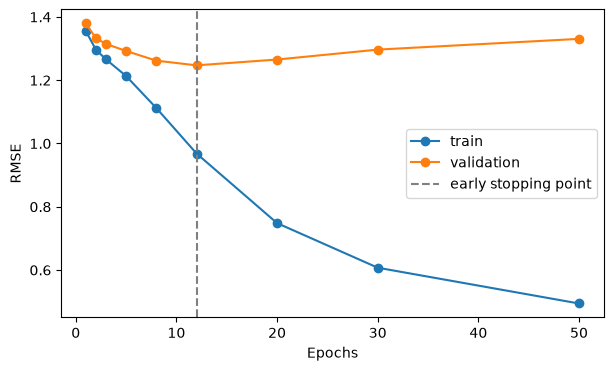

In [31]:
epochs_list = [1, 2, 3, 5, 8, 12, 20, 30, 50]
train_testset = tune_trainset.build_testset()

rows = []
for n_epochs in epochs_list:
    algo = SVD(n_factors=best_n_factors, n_epochs=n_epochs, random_state=my_seed)
    algo.fit(tune_trainset)
    rows.append({"epochs": n_epochs,
                 "train RMSE": accuracy.rmse(algo.test(train_testset), verbose=False),
                 "validation RMSE": accuracy.rmse(algo.test(tune_valset), verbose=False)})
epochs_df = pd.DataFrame(rows)

best_epochs = int(epochs_df.loc[epochs_df["validation RMSE"].idxmin(), "epochs"])
print("Epochs with the lowest validation RMSE:", best_epochs)

plt.figure(figsize=(7, 4))
plt.plot(epochs_df["epochs"], epochs_df["train RMSE"], marker="o", label="train")
plt.plot(epochs_df["epochs"], epochs_df["validation RMSE"], marker="o", label="validation")
plt.axvline(best_epochs, color="grey", linestyle="--", label="early stopping point")
plt.xlabel("Epochs")
plt.ylabel("RMSE")
plt.legend()
plt.show()

**Interpretation.** 

The train error falls with every epoch, from about 1.35 after one epoch to about 0.49 after 50, but the validation error only improves until 12 epochs (RMSE about 1.245) and then rises to about 1.33. After 12 epochs the model is fitting the noise in the training ratings instead of the users’ taste, which is overfitting. Training stops at 12 epochs, which is also better than the default of 20 (about 1.265). The epochs tested are 8, 12 and 20, so the best point lies somewhere between 8 and 20.

Latent factor 

In [33]:
svd_2d = SVD(n_factors=2, n_epochs=20, random_state=my_seed)
svd_2d.fit(trainset)

item_factors = pd.DataFrame(svd_2d.qi, columns=["dim 1", "dim 2"],
                            index=[trainset.to_raw_iid(i) for i in range(trainset.n_items)])
n_ratings = ratings_per_anime_df["count"].reindex(item_factors.index)

# Only anime with enough ratings, as the factors of rarely rated anime are not reliable
popular_factors = item_factors[n_ratings >= 200]
genres_popular = genres_df.reindex(popular_factors.index).fillna(0)
genre_corr = pd.DataFrame({dim: genres_popular.corrwith(popular_factors[dim]) for dim in popular_factors.columns}).dropna()

print("Anime in the plot:", len(popular_factors))
for dim in genre_corr.columns:
    ordered = genre_corr[dim].sort_values()
    print(dim, "- most negative genres:", list(ordered.index[:3]), " most positive genres:", list(ordered.index[-3:]))

Anime in the plot: 1168
dim 1 - most negative genres: ['Drama', 'Psychological', 'Mystery']  most positive genres: ['Harem', 'Ecchi', 'Comedy']
dim 2 - most negative genres: ['Harem', 'Ecchi', 'Romance']  most positive genres: ['Drama', 'Psychological', 'Dementia']


In [34]:
print(genre_corr.loc[["Drama", "Psychological", "Mystery", "Harem", "Ecchi", "Comedy", "Romance"]].round(2))
print("Correlation between the two factors:", round(popular_factors["dim 1"].corr(popular_factors["dim 2"]), 2))

               dim 1  dim 2
Drama          -0.28   0.17
Psychological  -0.25   0.18
Mystery        -0.22   0.10
Harem           0.24  -0.36
Ecchi           0.30  -0.36
Comedy          0.31  -0.01
Romance        -0.02  -0.22
Correlation between the two factors: -0.24


Latent factor plot

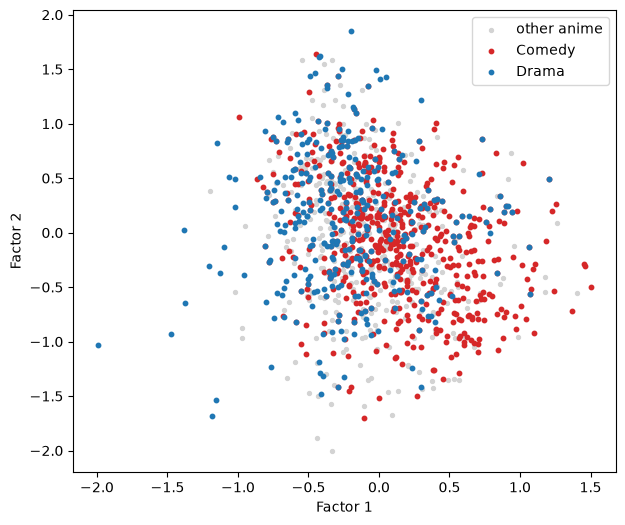

dim 1 low end:  ['School Days', 'Elfen Lied', 'Hoshi no Koe', 'Tenshi Kinryouku', 'Re:Zero kara Hajimeru Isekai Seikatsu']
dim 1 high end: ['Kiss x Sis (TV)', 'Aki-Sora: Yume no Naka', 'Naruto: Dai Katsugeki!! Yuki Hime Shinobu Houjou Dattebayo! Special: Konoha Annual Sports Festival', 'Naruto', 'Dragon Ball GT']
dim 2 low end:  ['Sword Art Online', 'Diabolik Lovers', 'Isekai wa Smartphone to Tomo ni.', 'Tokyo Ghoul √A', 'Seiken Tsukai no World Break']
dim 2 high end: ['Mononoke', 'Neon Genesis Evangelion: The End of Evangelion', 'Serial Experiments Lain', 'Yojouhan Shinwa Taikei', 'Texhnolyze']


In [35]:
genre_a = genre_corr["dim 1"].idxmax()
genre_b = genre_corr["dim 1"].idxmin()

plt.figure(figsize=(7, 6))
plt.scatter(popular_factors["dim 1"], popular_factors["dim 2"], s=8, color="lightgrey", label="other anime")
for genre, color in [(genre_a, "tab:red"), (genre_b, "tab:blue")]:
    in_genre = genres_popular[genre] == 1
    plt.scatter(popular_factors.loc[in_genre, "dim 1"], popular_factors.loc[in_genre, "dim 2"], s=10, color=color, label=genre)
plt.xlabel("Factor 1")
plt.ylabel("Factor 2")
plt.legend()
plt.show()

# The anime at the two ends of each factor
for dim in ["dim 1", "dim 2"]:
    ordered = popular_factors[dim].sort_values()
    print(dim, "low end: ", [titles[i] for i in ordered.index[:5]])
    print(dim, "high end:", [titles[i] for i in ordered.index[-5:]])

**Interpretation** 
The two factors place Comedy and Drama anime in different parts of the plane: Comedy anime lean toward the lower right and Drama anime toward the upper left. The groups overlap heavily, so two dimensions capture only the broadest difference in taste, between serious and light anime, and much of what users like depends on other things. The model was never given the genres, so the separation comes only from which anime the same users rated highly. The two factors describe the same contrast along a diagonal, which is why the strongest genres for factor 2 mirror those for factor 1. The sign and rotation of the axes are arbitrary.

NMF

In [36]:
nmf_tuning = pd.DataFrame([
    dict({"n_factors": n_factors}, **validate(NMF(n_factors=n_factors, random_state=my_seed)))
    for n_factors in [1, 15, 100]
])
print(nmf_tuning.round(3).to_string(index=False))
best_nmf_factors = int(nmf_tuning.sort_values("NDCG@10", ascending=False).iloc[0]["n_factors"])

 n_factors  RMSE  NDCG@10  MAP@10
         1 4.517    0.948   0.805
        15 2.155    0.943   0.787
       100 2.668    0.911   0.670


In [37]:
best_nmf_factors = 15  # 1 factor is a popularity ranking; the NDCG gap to 15 is within noise

**Interpretation** 
NMF predicts ratings much worse than SVD (RMSE 2.2 against 1.26 at best). Surprise’s NMF has no global mean or bias terms and has to rebuild every rating from non-negative factors, so its scores are on the wrong scale even when the order of the anime is reasonable. Its NDCG (0.943 to 0.948) is close to SVD’s. A very large number of factors overfits (100 factors: NDCG 0.911, MAP 0.670). One factor scores highest on NDCG, but it only reproduces popularity, and the difference from 15 factors is within what one validation split can resolve, so the default of 15 is kept. NMF is not expected to be the final choice for rating prediction.

Final comparison and baseline

In [38]:
cf_models = {
    "User KNN": KNNWithMeans(k=int(best_user["k"]), min_k=1, verbose=False,
                             sim_options={"name": "cosine", "user_based": True, "min_support": int(best_user["min_support"])}),
    "Item KNN": KNNWithMeans(k=int(best_item["k"]), min_k=1, verbose=False,
                             sim_options={"name": "cosine", "user_based": False, "min_support": int(best_item["min_support"])}),
    "SVD": SVD(n_factors=best_n_factors, n_epochs=best_epochs, random_state=my_seed),
    "NMF": NMF(n_factors=best_nmf_factors, random_state=my_seed),
}

results_cf = {name: evaluate_model(algo) for name, algo in cf_models.items()}
results_part3_df = pd.concat([results_part2_df, pd.DataFrame(results_cf).T])
results_part3_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.344,1.855,0.860,0.557,0.388,0.812,0.033,3.1,80.88,0.998,0.179
Popular,1.552,1.184,0.932,0.784,0.509,0.912,0.000,0.0,0.31,0.077,0.141
Bayesian popular,1.586,1.208,0.931,0.780,0.507,0.910,0.875,49.2,1.24,0.407,0.267
Demographic,1.565,1.190,0.932,0.784,0.508,0.912,0.777,47.0,1.51,0.523,0.314
User KNN,1.284,0.971,0.935,0.794,0.517,0.914,0.005,0.5,2.55,0.414,0.124
Item KNN,1.265,0.945,0.936,0.796,0.516,0.919,0.007,0.7,2.19,0.305,0.134
SVD,1.229,0.919,0.939,0.805,0.521,0.922,0.573,33.0,7.29,0.807,0.281
NMF,2.150,1.883,0.926,0.762,0.496,0.903,0.039,3.9,4.49,0.556,0.163


**Final comparison** SVD is the best model on rating accuracy (RMSE 1.23 against 1.55 for popularity) and on ranking within each user’s test items (NDCG@10 over users with 20+ test items: 0.922 against 0.912). It also gives the broadest and most personalised recommendations (coverage 7.3%, personalization 0.81). On the more demanding homepage test, though, Bayesian popular places 0.88 relevant titles in a user’s top 10 and reaches 49% of users, against 0.57 and 33% for SVD, because most users end up watching popular anime. Neighbourhood models predicted ratings well but initially failed on the homepage task: with min_k=1 an anime rated by a single neighbour can be ranked first, so the top 10 fills with obscure titles. Requiring at least 5 neighbours addresses this. NMF is the weakest personalised model, as Surprise’s version has no bias terms. The business trade-off is that popularity is the safer homepage default, while SVD adds personalisation and catalogue coverage.

# Part 5. Hybrid

To be added.

# Part 6. Context-aware

To be added.

# Part 7. Bandits

To be added.

# Part 8. Final comparison and business value

To be added.

# References

[1] Aggarwal, C. C. (2016). Recommender Systems: The Textbook. Springer.

[2] Falk, K. (2019). Practical Recommender Systems. Manning.

[3] S05 notebook. Key data for building recommendation systems.

[4] S08 notebook. Practical exercises on performance metrics.

[5] S10 notebook. Data splitting and evaluation methods.

[6] S20 notebook. Offline vs online evaluation, hyperparameter tuning and A/B testing strategy.

[7] Impact of long-tail into performance metrics notebook.

[8] Class notes, Session 16.

[9] A4 Build your own non-personalized recommender (assignment brief).

[10] Google Colab. Past runtime versions FAQ. https://research.google.com/colaboratory/runtime-version-faq.html

[11] A3 Expected performance of non-personalized recommenders (assignment brief).

[12] S06 slides. Approaches to building recommenders: collaborative, content-based and hybrid.

[13] S09 notebook. Building non-personalized recommenders.

[14] Class notes, Sessions 1 to 18.